## 5. Réseau du neurones sur le dataset Titanic

##### Etape 1: Importer les libraires

In [1]:
#importing libraries from libs.py

from libs import *        # np, pd, plt, tf, keras, layers, train_test_split, ...

tf.keras.utils.set_random_seed(42)

#### Étape 2 — Charger le datasets - Titanic

In [2]:
import seaborn as sns

titanic = sns.load_dataset("titanic")

##### Etape 3: Data Exploration

In [3]:
display(titanic.head(5))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Repérer les valeurs manquantes
titanic.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

#### 1. Choisir les colonnes/features pertinentes

In [5]:
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = titanic[features]
y = titanic["survived"].values

#### 2. Séparer les données en Train et Test

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

#### 3. Gérer les valeurs manquantes

In [7]:
age_median = X_train['age'].mean()
embarked_mode = X_train['embarked'].mode()[0]

X_train = X_train.fillna({'age':age_median, 'embarked': embarked_mode})
X_test = X_test.fillna({'age': age_median, 'embarked':embarked_mode})

print("Valeurs manquantes restantes : ", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Valeurs manquantes restantes :  0 0


#### 4. Encoder les variables catégorielles

In [8]:
cat = ['sex', 'embarked', 'pclass']
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train.head()

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3
692,29.807687,0,0,56.4958,True,False,True,False,True
481,29.807687,0,0,0.0000,True,False,True,True,False
527,29.807687,0,0,221.7792,True,False,True,False,False
855,18.000000,0,1,9.3500,False,False,True,False,True
801,31.000000,1,1,26.2500,False,False,True,True,False


#### 5. Normaliser les features numériques

In [9]:
num = ['age', 'fare']
class standardScaler:
    def __init__(self):
        self.mean_ = None
        self.scale_ = None

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.scale_[self.scale_ == 0] = 1.0
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if self.mean_ is None or self.scale_ is None:
            raise ValueError("The scaler must be fitted before calling transform().")
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)

scaler = standardScaler()
X_train[num] = scaler.fit_transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

print(X_train.head())

              age  sibsp  parch      fare  sex_male  embarked_Q  embarked_S  \
692 -5.463229e-16      0      0  0.513812      True       False        True   
481 -5.463229e-16      0      0 -0.662563      True       False        True   
527 -5.463229e-16      0      0  3.955399      True       False        True   
855 -9.078708e-01      0      1 -0.467874     False       False        True   
801  9.167471e-02      1      1 -0.115977     False       False        True   

     pclass_2  pclass_3  
692     False      True  
481      True     False  
527     False     False  
855     False      True  
801      True     False  


#### 6. Conversion en numpy array

In [10]:
feature_names = list(X_train.columns)
X_train = X_train.values.astype('float32')
X_test = X_test.values.astype('float32')

#### 7. Vérifier les dimensions

In [11]:
print("Shape X_train:", X_train.shape)
print("Shape y_train:", y_train.shape)
print("Shape X_test:", X_test.shape)

Shape X_train: (712, 9)
Shape y_train: (712,)
Shape X_test: (179, 9)


#### 8. Construire le modèle

In [12]:
from tensorflow.keras.models import Sequential

model = Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(27, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 27)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 298 (1.16 KB)

 Trainable params: 298 (1.16 KB)

 Non-trainable params: 0 (0.00 B)

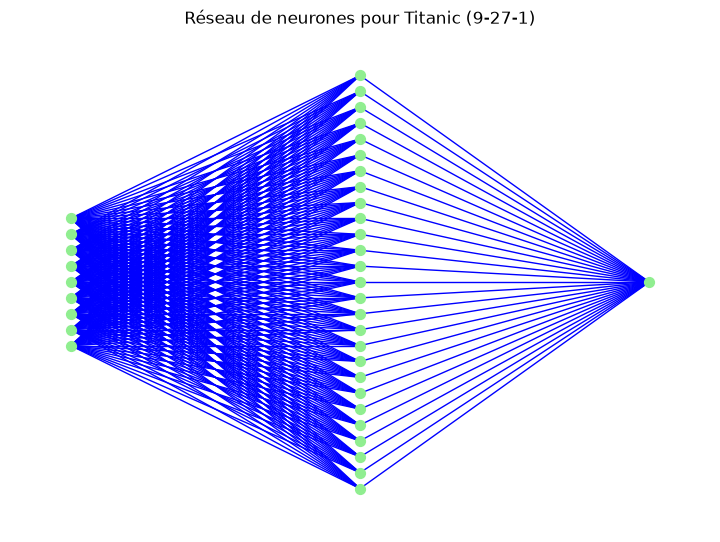

In [13]:
import networkx as nx

layers = [9, 27, 1]

G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layers):
    layer_pos = []
    offset = (n_neurons - 1) / 2              # centre each layer vertically
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, offset - i)        # neurons in columns
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)         # <-- fix: node names, not `layers`

for l in range(len(layers) - 1):
    for src in layer_positions[l]:
        for dst in layer_positions[l + 1]:
            G.add_edge(src, dst)

plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=False, node_size=50,
        node_color="lightgreen", edge_color="blue", arrows=False)
plt.title("Réseau de neurones pour Titanic (9-27-1)", fontsize=12)
plt.show()

#### 9. Compiler et entraîner ke modèle

In [14]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer='adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [15]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.1, callbacks=[early_stop])

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.5359 - loss: 0.7166 - val_accuracy: 0.6111 - val_loss: 0.6428
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7063 - loss: 0.6603 - val_accuracy: 0.7917 - val_loss: 0.6032
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7328 - loss: 0.6221 - val_accuracy: 0.8056 - val_loss: 0.5743
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7281 - loss: 0.5945 - val_accuracy: 0.7778 - val_loss: 0.5520
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7234 - loss: 0.5735 - val_accuracy: 0.7778 - val_loss: 0.5327
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7344 - loss: 0.5567 - val_accuracy: 0.7917 - val_loss: 0.5169
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7516 - loss: 0.5428 - val_accuracy: 0.7778 - val_loss: 0.5035
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7547 - loss: 0.5307 - val_accuracy: 0.7778 - val_loss

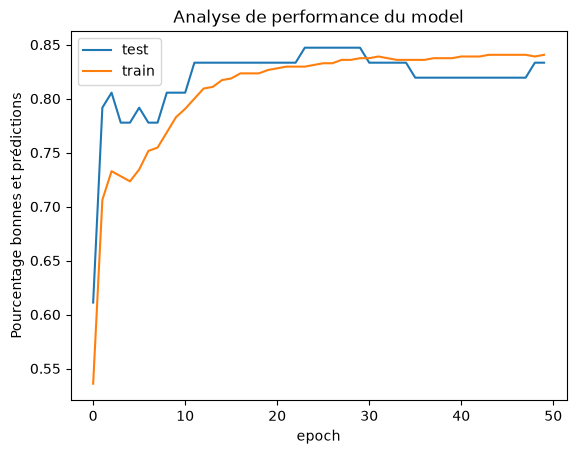

In [16]:
# Analyse de performance du model en graph
plt.plot(history.history["val_accuracy"])
plt.plot(history.history["accuracy"])
plt.title("Analyse de performance du model")
plt.xlabel("epoch")
plt.ylabel("Pourcentage bonnes et prédictions")
plt.legend(["test", "train"])

In [17]:
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"Test Accuracy: {acc * 100:.2f}%")

6/6 - 0s - 13ms/step - accuracy: 0.8101 - loss: 0.4537
Test Accuracy: 81.01%


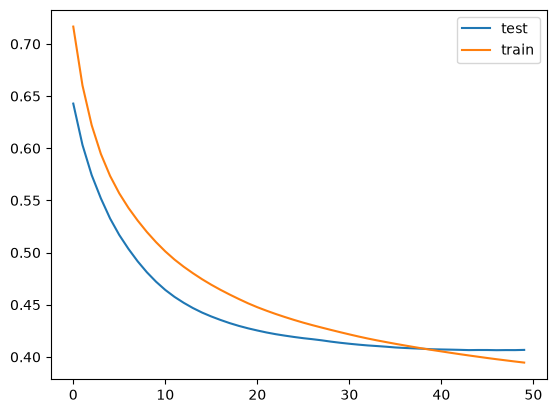

In [18]:
plt.plot(history.history["val_loss"])
plt.plot(history.history["loss"])
plt.legend(["test", "train"])

#### 10. Evaluer le mmodèle sur le test set

In [19]:
predictions = model.predict(X_test)
y_pred = (predictions > 0.5).astype(int).ravel()

df_test = pd.DataFrame(X_test, columns=feature_names)
df_test[num] = df_test[num] * scaler.scale_ + scaler.mean_

df_test["age"] = df_test["age"].round().astype(int)
df_test["sibsp"] = df_test["sibsp"].round().astype(int)
df_test["parch"] = df_test["parch"].round().astype(int)
df_test["fare"] = df_test["fare"].round().astype(int)

df_test["True_Class"] = y_test
df_test["Predicted_Class"] = y_pred
df_test["Proba"] = predictions.ravel().round(3)
df_test["correct"] = df_test["True_Class"] == df_test["Predicted_Class"]

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [20]:
df_test.head(5)

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3,True_Class,Predicted_Class,Proba,correct
0,24,2,0,24,1.0,0.0,1.0,0.0,1.0,0,0,0.139,True
1,44,0,1,16,1.0,0.0,1.0,0.0,1.0,0,0,0.068,True
2,22,0,0,7,1.0,0.0,0.0,0.0,1.0,1,0,0.226,False
3,41,2,0,14,1.0,0.0,1.0,0.0,1.0,0,0,0.133,True
4,30,1,0,16,0.0,1.0,0.0,0.0,1.0,1,1,0.691,True


In [21]:
df_test['correct'].value_counts()

correct
True     145
False     34
Name: count, dtype: int64

##### 11: Visualiser la prédiction pour quelques exemples

In [22]:
# X_test is already encoded and normalized, shape (N, 9)
predictions = model.predict(X_test, batch_size=256)
pred_classes = (predictions.ravel() >= 0.5).astype(int)

print("Probabilités (premières 3) :\n", predictions[:3].round(3))
print("Classes prédites :", pred_classes[:20])
print("Vraies classes   :", y_test[:20])
print("Accuracy :", (pred_classes == y_test).mean())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Probabilités (premières 3) :
 [[0.139]
 [0.068]
 [0.226]]
Classes prédites : [0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 1]
Vraies classes   : [0 0 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]
Accuracy : 0.8100558659217877


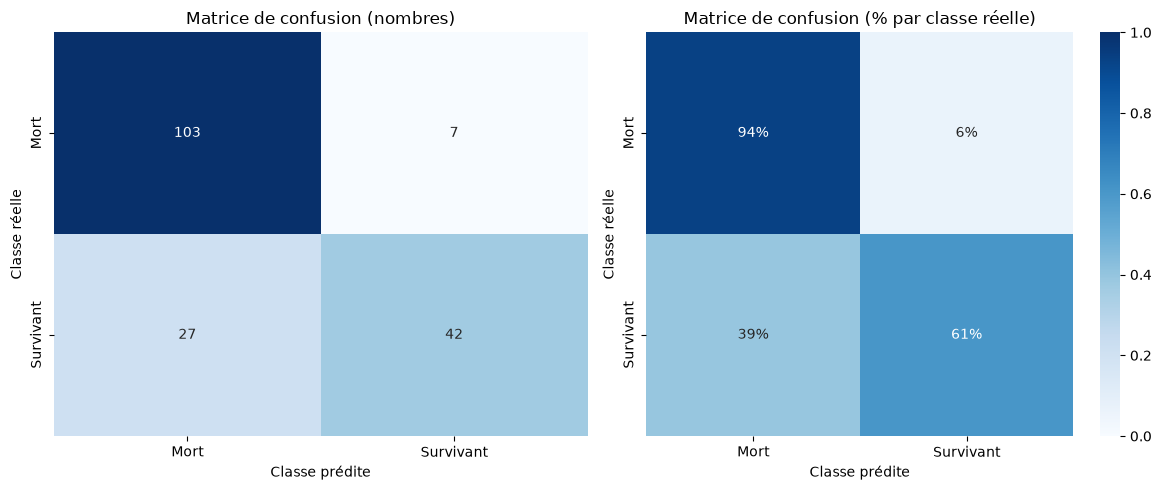

In [23]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = ["Mort", "Survivant"]

# Sigmoid output (1 neuron): threshold at 0.5, no argmax
y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)         # % per real class

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, cbar=False)
axes[0].set_title("Matrice de confusion (nombres)")

sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
axes[1].set_title("Matrice de confusion (% par classe réelle)")

for ax in axes:
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")

plt.tight_layout()
plt.show()


In [24]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))


              precision    recall  f1-score   support

        Mort       0.79      0.94      0.86       110
   Survivant       0.86      0.61      0.71        69

    accuracy                           0.81       179
   macro avg       0.82      0.77      0.79       179
weighted avg       0.82      0.81      0.80       179

